In [1]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/manifold/../../../../utils/train_utils.py'>

In [3]:
dims = 3

read_ids = list(range(0, 12+1))
# read_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# read_ids = [0]
plot_id = 0

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
# prep

def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

In [6]:
selection_bhl = ['walk', 'still', 'front-groom', 'back-groom', 'abdomen-move', 'background']

plot_idx = file_ids.index(plot_id)

# states = [ds[selection_bhl] for ds in states]

In [7]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, zscore=False,
												 n_pc=dims)

In [8]:
save = False

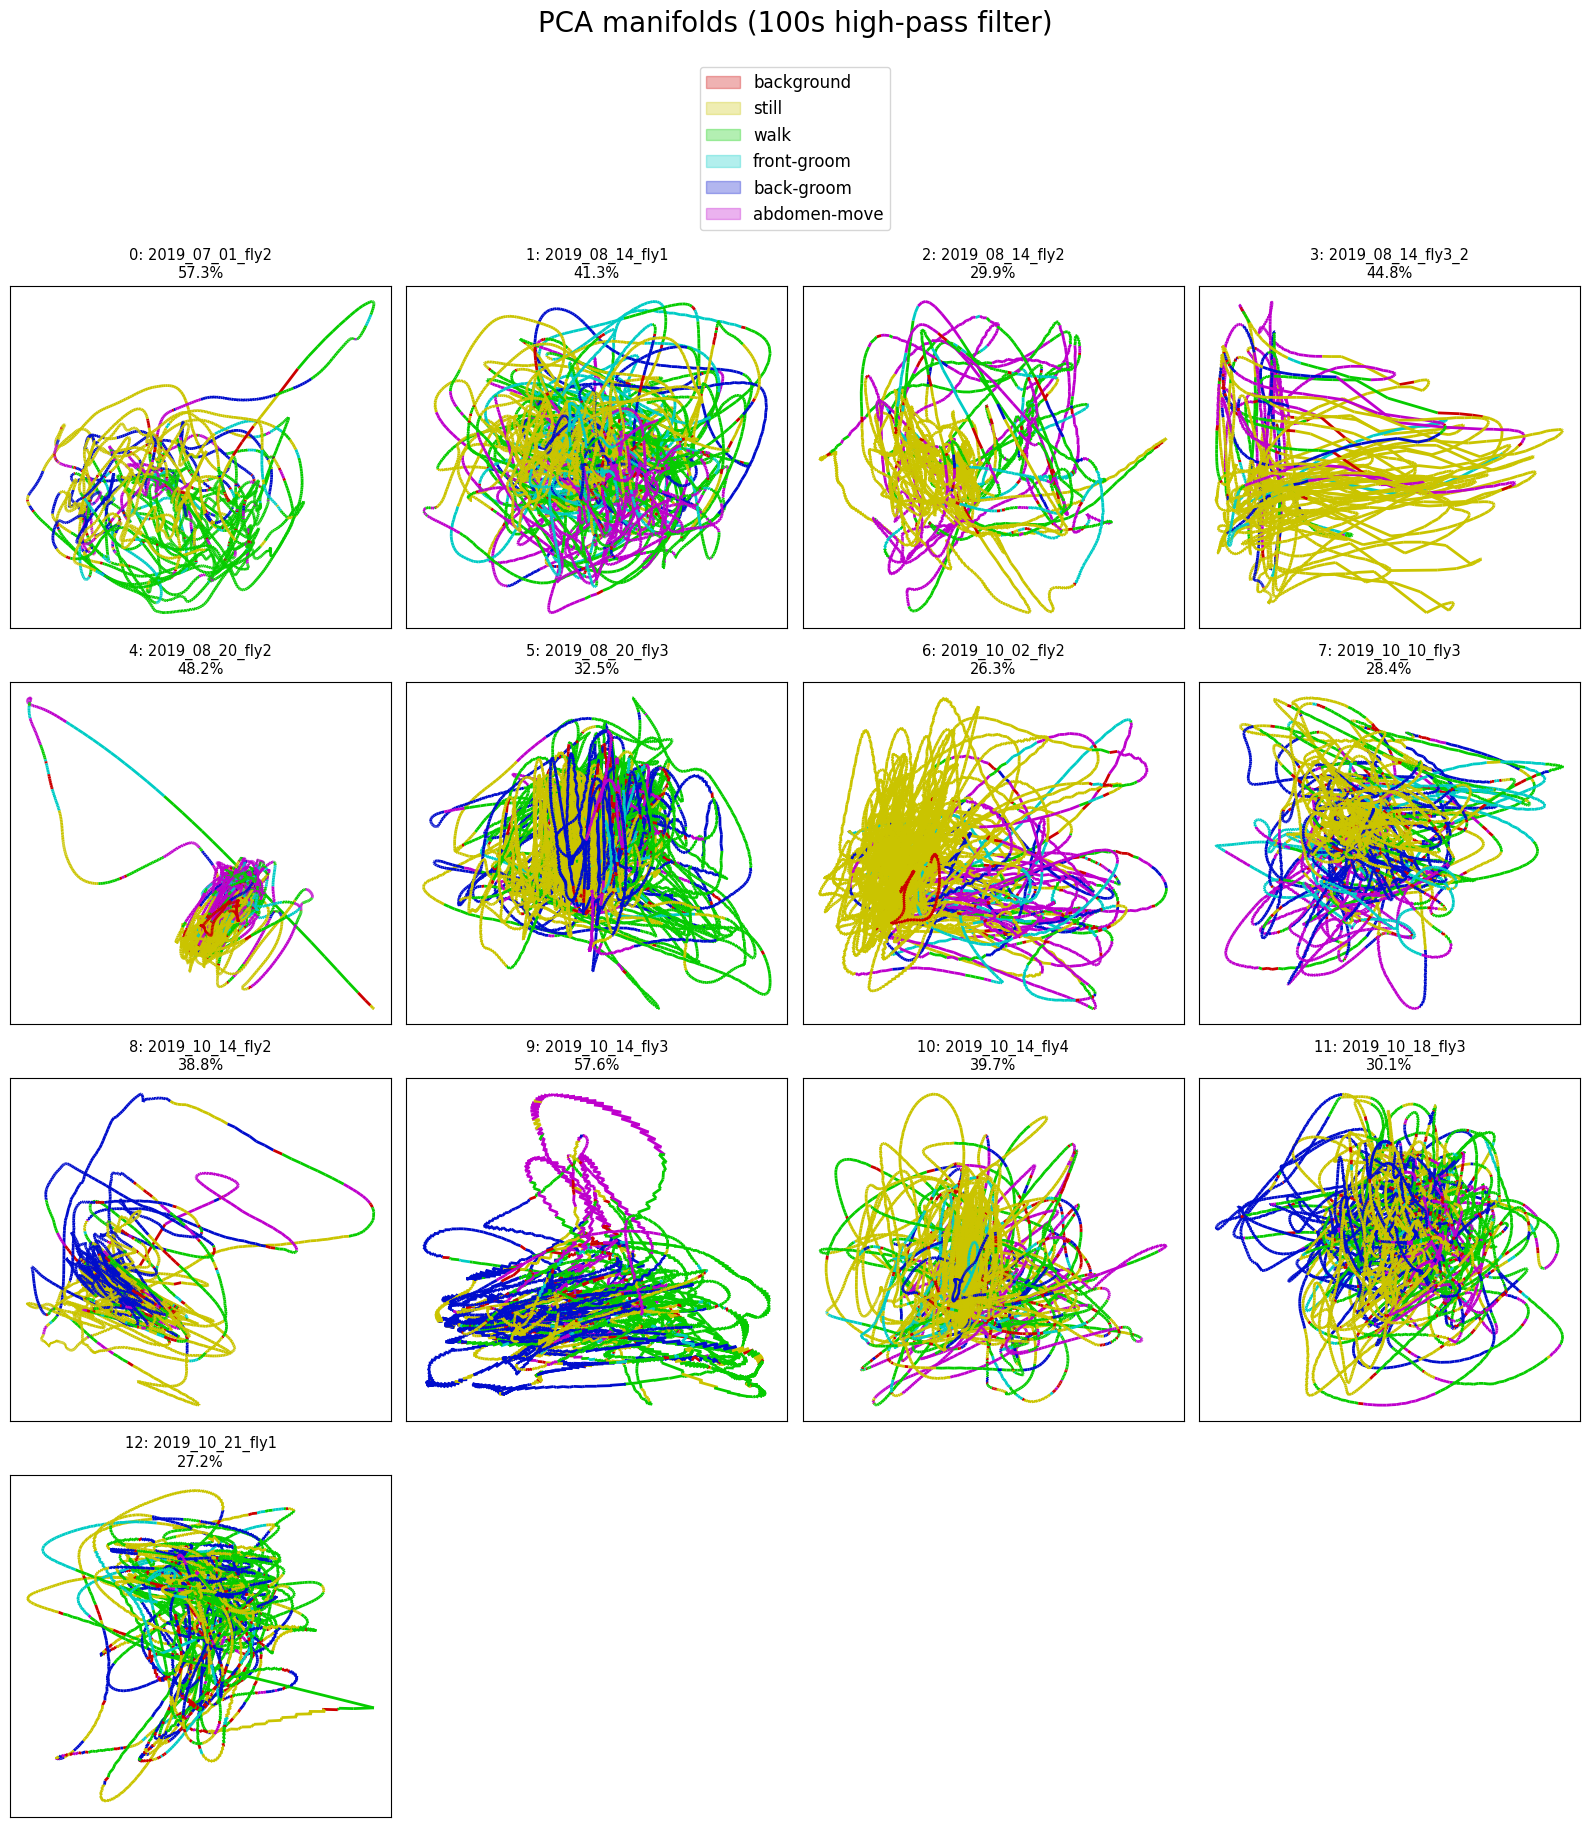

38.6%


In [9]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, states,
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PCA manifolds (100s high-pass filter)', top_space=2.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PCA' if save else None)

In [10]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, states,
# 							 [vx[:3] for vx in vars_expl_mans], None,
# 							 title='PCA manifolds (100s high-pass filter)', top_space=3,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_3d' if save else None)

In [11]:
for i, trace in enumerate(traces):
	print(np.mean(trace.values, axis=0))

[ 2.37185867e-05  1.04967881e-05 -1.72755488e-06 ...  8.11570176e-06
  8.54363303e-06  1.02351925e-05]
[-1.80297369e-06  3.02665198e-05 -5.31332765e-06 ... -1.50346096e-08
  2.09294611e-05 -2.17224570e-05]
[-2.47045681e-05  9.38844621e-05  1.08397257e-04 ...  1.61152178e-05
  1.28445804e-05  7.75366618e-06]
[-6.99085150e-05 -3.36374042e-05  7.87121767e-05 ... -1.14272440e-05
 -7.04881950e-05  5.21399589e-05]
[-2.10522827e-04 -1.29863583e-04 -1.97200572e-04 -2.10153632e-04
 -2.57761756e-04 -1.51589393e-04 -2.08322665e-04 -1.41747443e-04
 -3.77318334e-04 -1.03474285e-04 -2.57781011e-04 -3.37957808e-04
 -2.16973836e-04 -1.20542404e-04 -1.30678219e-04 -1.10101478e-04
  1.62759545e-05 -1.73857437e-04 -7.77820746e-05 -7.42820953e-05
 -3.17062024e-04 -3.12328765e-04 -2.77342558e-04 -1.59463623e-04
 -5.95768371e-05 -1.50942274e-04 -4.95224330e-05 -1.18319521e-04
 -2.04051159e-04 -2.24603556e-04 -1.55857306e-04 -1.27883227e-04
 -1.89646775e-04 -1.21821666e-04 -2.46636254e-04 -5.63355553e-05
 -8

In [12]:
traces_residual = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

for i, trace in enumerate(traces_residual):
	print(np.mean(trace.values, axis=0))

[-3.26406496e-19 -9.43763298e-20  6.33185103e-20 ...  9.97733362e-20
  1.21493983e-19 -2.26893097e-19]
[-1.61184382e-20 -3.02492008e-19  4.14167730e-20 ...  2.91432953e-20
  2.43012301e-20  5.10938015e-20]
[-1.74184690e-19 -5.78523834e-19  5.25833107e-19 ... -4.83947653e-19
 -8.67177999e-20 -2.95113302e-19]
[-2.23890266e-20  8.36896393e-19 -1.67946751e-19 ...  4.07495779e-20
  1.52539770e-19 -9.17252856e-20]
[ 2.27564710e-20  3.09485330e-19  1.89598233e-19  1.63172226e-20
  6.85102576e-20 -3.33168383e-21 -9.48660176e-21  4.52654073e-20
  1.31263660e-19 -1.79817265e-19  2.05453836e-19  2.20867892e-19
  2.35224907e-20 -1.37013825e-20 -8.02781931e-20 -1.03027974e-19
 -8.76005384e-20  4.36932271e-20  3.43872588e-20  6.88882498e-20
  1.24918073e-19 -1.16107175e-19  5.88731280e-22  5.62639780e-21
 -9.39829206e-20  2.68233999e-19  4.71495146e-20 -5.49928536e-21
  1.09356835e-19  8.91660284e-20 -5.52203180e-20  6.54930098e-20
  1.56856745e-19  6.60984664e-21 -6.87009263e-20 -1.17833228e-19
  7

In [13]:
raise Exception

Exception: 

In [ ]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :])[::-1] for xloads_pca_man in loads_pca_man]

traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]

traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]

traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]

# fly 0

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_sorted[file_ids.index(0)],
	None,
	'traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[file_ids.index(0)],
	None,
	'manifold', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[file_ids.index(0)],
	None,
	'residuals', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

# fly 2

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_sorted[file_ids.index(2)],
	None,
	'traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[file_ids.index(2)],
	None,
	'manifold', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[file_ids.index(2)],
	None,
	'residuals', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

# fly 3

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_sorted[file_ids.index(3)],
	None,
	'traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[file_ids.index(3)],
	None,
	'manifold', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[file_ids.index(3)],
	None,
	'residuals', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

# fly 8


In [ ]:
plot_utils.plot_heatmap_stack(
	traces_sorted[file_ids.index(8)],
	None,
	'traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[file_ids.index(8)],
	None,
	'manifold', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[file_ids.index(8)],
	None,
	'residuals', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

# fly 9

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_sorted[file_ids.index(9)],
	None,
	'traces', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_manifolds_sorted[file_ids.index(9)],
	None,
	'manifold', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_residuals_sorted_by_manifold[file_ids.index(9)],
	None,
	'residuals', None,
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=True)